## CAI501-AIE501: AI Systems

##### *Assignment 1: A Fair Four-Arm Fine-Tuning Study*

###### Transfer Learning and Fine-Tuning

In [1]:
import gc
import json
import platform
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet18_Weights, resnet18

##### Experiment Map
A: Training from scratch (random weights, every layer trained)

B: Linear probing (frozen ImageNet backbone, new head only)

C: Partial fine-tuning (head only for epochs 1-10, then `layer4` + head for epochs 11-40)

D: Full fine-tuning (ImageNet weights, every layer trained)

## Step Zero: Setup

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

SPLIT_SEED = 2026
TRAIN_SEEDS = [11, 22, 33]
EPOCHS = 40
STAGE2_START = 11  # Experiment C: layer4 joins at epoch 11
BATCH_SIZE = 32
WEIGHT_DECAY = 1e-4
IMAGE_SIZE = 224
SHIFT_BRIGHTNESS = 0.6

DATA_DIR = Path("data")
SPLIT_DIR = Path("splits")
RESULT_DIR = Path("results")
FIGURE_DIR = Path("figures")
for folder in (SPLIT_DIR, RESULT_DIR, FIGURE_DIR):
    folder.mkdir(exist_ok=True)

print("Device:     ", device)
print("Platform:   ", platform.platform())
print("Python:     ", platform.python_version())
print("PyTorch:    ", torch.__version__)
print("Torchvision:", torchvision.__version__)

Device:      mps
Platform:    macOS-27.2-arm64-arm-64bit
Python:      3.12.13
PyTorch:     2.15.0
Torchvision: 0.29.2


In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def allocated_mb():
    if device.type == "cuda":
        return torch.cuda.max_memory_allocated() / 2**20
    if device.type == "mps":
        return torch.mps.current_allocated_memory() / 2**20  # MPS has no peak counter, so we sample
    return float("nan")


def reset_memory():
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    elif device.type == "mps":
        torch.mps.empty_cache()

In [4]:
COLORS = {"A": "#52514e", "B": "#2a78d6", "C": "#eb6834", "D": "#1baf7a"}  # A (baseline) in gray
MARKERS = {"A": "o", "B": "s", "C": "^", "D": "D"}

pd.set_option("display.max_colwidth", None)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "lines.linewidth": 1.6,
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

## 2. Dataset

### Restrict CIFAR-10 to two categories: Cat (index 3 → 0) and Dog (index 5 → 1)

In [5]:
CLASS_MAP = {3: 0, 5: 1}  # original CIFAR-10 index -> binary label
CLASS_NAMES = ["Cat", "Dog"]

cifar_train = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
cifar_test = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)

train_targets = np.array(cifar_train.targets)
test_targets = np.array(cifar_test.targets)

### Create the training and validation sets from the official training split (seed 2026)

In [6]:
rng = np.random.default_rng(SPLIT_SEED)

train_parts, val_parts = [], []
for original in CLASS_MAP:  # cat first, then dog
    ids = rng.permutation(np.where(train_targets == original)[0])
    train_parts.append(ids[:200])
    val_parts.append(ids[200:400])

train_ids = np.concatenate(train_parts)
val_ids = np.concatenate(val_parts)

### Use the official CIFAR-10 test split for final evaluation

In [7]:
test_ids = np.where(np.isin(test_targets, list(CLASS_MAP)))[0]

### Check the partition sizes and that training and validation never share an image

In [8]:
partitions = {
    "Training": (train_targets, train_ids),
    "Validation": (train_targets, val_ids),
    "Testing": (test_targets, test_ids),
}

for name, (targets, ids) in partitions.items():
    cats, dogs = np.bincount([CLASS_MAP[t] for t in targets[ids]], minlength=2)
    print(f"{name:<11} Cat: {cats:>5}   Dog: {dogs:>5}   Total: {len(ids):>5}")

shared = len(np.intersect1d(train_ids, val_ids))
assert shared == 0
print("\nImages shared by training and validation:", shared)

Training    Cat:   200   Dog:   200   Total:   400
Validation  Cat:   200   Dog:   200   Total:   400
Testing     Cat:  1000   Dog:  1000   Total:  2000

Images shared by training and validation: 0


### Save the image IDs and class mapping

In [9]:
def save_ids(ids, targets, split, file_name):
    frame = pd.DataFrame({
        "cifar_split": split,
        "cifar_index": ids,
        "cifar_label": targets[ids],
        "label": [CLASS_MAP[t] for t in targets[ids]],
    })
    frame["class_name"] = frame["label"].map(dict(enumerate(CLASS_NAMES)))
    frame["rank_in_class"] = frame.groupby("label").cumcount()  # first n per class = nested subset
    frame.to_csv(SPLIT_DIR / file_name, index=False)
    return frame


train_frame = save_ids(train_ids, train_targets, "train", "train_ids.csv")
save_ids(val_ids, train_targets, "train", "val_ids.csv")
save_ids(test_ids, test_targets, "test", "test_ids.csv")

class_mapping = {
    "split_seed": SPLIT_SEED,
    "classes": [{"cifar_index": k, "cifar_name": CLASS_NAMES[v].lower(), "label": v} for k, v in CLASS_MAP.items()],
}
(SPLIT_DIR / "class_mapping.json").write_text(json.dumps(class_mapping, indent=2))

train_frame.head()

,cifar_split,cifar_index,cifar_label,label,class_name,rank_in_class
0,train,24348,3,0,Cat,0
1,train,41725,3,0,Cat,1
2,train,20963,3,0,Cat,2
3,train,25235,3,0,Cat,3
4,train,19781,3,0,Cat,4


### Resize to 224 × 224, ImageNet normalization, random augmentation on the training set only

> Same augmentation for all four experiments: random crop (padding 4) and horizontal flip at 32 × 32, then resize.

In [10]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet

train_tf = T.Compose([
    T.RandomCrop(32, padding=4, padding_mode="reflect"),
    T.RandomHorizontalFlip(),
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

eval_tf = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

shift_tf = T.Compose([
    T.Lambda(lambda image: TF.adjust_brightness(image, SHIFT_BRIGHTNESS)),  # original image, before normalization
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

In [11]:
class CatDog(Dataset):
    def __init__(self, base, ids, transform):
        self.base, self.ids, self.transform = base, ids, transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        image, target = self.base[int(self.ids[i])]
        return self.transform(image), CLASS_MAP[target]


val_loader = DataLoader(CatDog(cifar_train, val_ids, eval_tf), batch_size=128)
test_loader = DataLoader(CatDog(cifar_test, test_ids, eval_tf), batch_size=128)
shift_loader = DataLoader(CatDog(cifar_test, test_ids, shift_tf), batch_size=128)

### Brightness-shifted test images (factor 0.6)

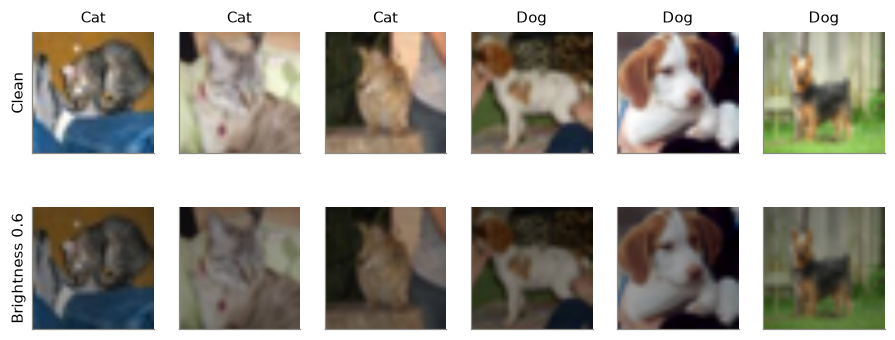

In [12]:
examples = np.concatenate([test_ids[test_targets[test_ids] == original][:3] for original in CLASS_MAP])  # 3 cats, 3 dogs

fig, axes = plt.subplots(2, 6, figsize=(10, 3.8))
for col, i in enumerate(examples):
    image, target = cifar_test[int(i)]
    axes[0, col].imshow(TF.resize(image, [IMAGE_SIZE, IMAGE_SIZE]))
    axes[1, col].imshow(TF.resize(TF.adjust_brightness(image, SHIFT_BRIGHTNESS), [IMAGE_SIZE, IMAGE_SIZE]))
    axes[0, col].set_title(CLASS_NAMES[CLASS_MAP[target]], fontsize=10)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
axes[0, 0].set_ylabel("Clean")
axes[1, 0].set_ylabel("Brightness 0.6")
fig.savefig(FIGURE_DIR / "brightness_shift_examples.png")
plt.show()

## 3. Required Neural Network

### ResNet-18 with a new 512 → 2 classification head

In [13]:
def build_model(pretrained):
    weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, 2)  # 512 -> 2
    return model


model = build_model(pretrained=True)
TOTAL_PARAMS = sum(p.numel() for p in model.parameters())

print("Classifier head: ", model.fc)
print("Total parameters:", f"{TOTAL_PARAMS:,}")

Classifier head:  Linear(in_features=512, out_features=2, bias=True)
Total parameters: 11,177,538


## 4. Required Experiments

### Freezing and BatchNorm treatment
A, D: every layer trainable; every BatchNorm layer in train mode.

B: backbone frozen; every backbone BatchNorm layer stays in eval mode.

C: stage 1 as B. Stage 2: BatchNorm layers inside `layer4` switch to train mode; `conv1` to `layer3` stay in eval mode.

> Rule: a BatchNorm layer updates its running statistics only when its own weights are trainable.

In [14]:
def set_trainable(model, prefixes):  # prefixes=None trains every layer
    for name, p in model.named_parameters():
        p.requires_grad = prefixes is None or name.startswith(tuple(prefixes))


def train_mode(model):
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d) and not module.weight.requires_grad:
            module.eval()  # frozen BatchNorm keeps its running statistics


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Experiment A: Training From Scratch

In [15]:
EXPERIMENTS = {}
EXPERIMENTS["A"] = {"name": "From Scratch", "pretrained": False, "stages": {1: None}}

### Experiment B: Frozen Feature Extraction (Linear Probing)

In [16]:
EXPERIMENTS["B"] = {"name": "Linear Probe", "pretrained": True, "stages": {1: ["fc"]}}

### Experiment C: Partial Fine-Tuning
> Stage 1 (epochs 1-10): head only. Stage 2 (epochs 11-40): `layer4` + head, `layer4` at a lower learning rate.

> Checkpoints are selected from stage 2 only, so the reported model is always partially fine-tuned.

In [17]:
EXPERIMENTS["C"] = {"name": "Partial Fine Tuning", "pretrained": True, "stages": {1: ["fc"], STAGE2_START: ["layer4", "fc"]}}

### Experiment D: Full Fine-Tuning

In [18]:
EXPERIMENTS["D"] = {"name": "Full Fine Tuning", "pretrained": True, "stages": {1: None}}

### Report the number of trainable parameters

In [19]:
for key, spec in EXPERIMENTS.items():
    model = build_model(spec["pretrained"])
    for start, prefixes in spec["stages"].items():
        set_trainable(model, prefixes)
        print(f"{key}: {spec['name']:<20} from epoch {start:>2}   trainable: {count_trainable(model):>10,} of {TOTAL_PARAMS:,}")

A: From Scratch         from epoch  1   trainable: 11,177,538 of 11,177,538


B: Linear Probe         from epoch  1   trainable:      1,026 of 11,177,538


C: Partial Fine Tuning  from epoch  1   trainable:      1,026 of 11,177,538
C: Partial Fine Tuning  from epoch 11   trainable:  8,394,754 of 11,177,538


D: Full Fine Tuning     from epoch  1   trainable: 11,177,538 of 11,177,538


### Training loop shared by all four experiments

In [20]:
def apply_stage(model, optimizer, prefixes, lrs):
    set_trainable(model, prefixes)
    if optimizer is None:
        head = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("fc")]
        backbone = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("fc")]
        groups = [{"params": head, "lr": lrs["head"]}]
        if backbone:
            groups.append({"params": backbone, "lr": lrs["backbone"]})
        return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

    known = {id(p) for group in optimizer.param_groups for p in group["params"]}
    unfrozen = [p for p in model.parameters() if p.requires_grad and id(p) not in known]
    optimizer.add_param_group({"params": unfrozen, "lr": lrs["backbone"]})  # pretrained layers, lower rate
    return optimizer


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, labels, preds, forward_s = 0.0, [], [], 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        sync()
        start = time.perf_counter()
        logits = model(x)
        sync()
        forward_s += time.perf_counter() - start
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        labels.append(y.cpu())
        preds.append(logits.argmax(1).cpu())
    labels, preds = torch.cat(labels).numpy(), torch.cat(preds).numpy()
    return loss_sum / len(labels), labels, preds, forward_s


def test_metrics(model, loader, prefix):
    _, labels, preds, forward_s = evaluate(model, loader)
    precision, recall, _, _ = precision_recall_fscore_support(labels, preds, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(labels, preds, labels=[0, 1])  # rows: true class, columns: predicted class
    return {
        f"{prefix}_acc": accuracy_score(labels, preds),
        f"{prefix}_macro_f1": f1_score(labels, preds, average="macro"),
        f"{prefix}_precision_cat": precision[0],
        f"{prefix}_recall_cat": recall[0],
        f"{prefix}_precision_dog": precision[1],
        f"{prefix}_recall_dog": recall[1],
        f"{prefix}_cm_cat_cat": int(cm[0, 0]),
        f"{prefix}_cm_cat_dog": int(cm[0, 1]),
        f"{prefix}_cm_dog_cat": int(cm[1, 0]),
        f"{prefix}_cm_dog_dog": int(cm[1, 1]),
        f"{prefix}_forward_s": forward_s,
    }

In [21]:
def run_experiment(key, seed, lrs, ids, test=True, verbose=True):
    spec = EXPERIMENTS[key]
    reset_memory()
    set_seed(seed)

    model = build_model(spec["pretrained"]).to(device)
    loader = DataLoader(CatDog(cifar_train, ids, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    start_params = {n: p.detach().clone() for n, p in model.named_parameters()}
    start_bn = {n: b.detach().clone() for n, b in model.named_buffers()}
    first_eligible = max(spec["stages"])  # C: stage 2 checkpoints only

    optimizer, trained, history, best = None, set(), [], None
    steps, train_time, peak_mb, first_trainable = 0, 0.0, 0.0, None

    if verbose:
        print(f"\n--------\n{key}: {spec['name']} | seed {seed}\n--------")

    for epoch in range(1, EPOCHS + 1):
        if epoch in spec["stages"]:
            optimizer = apply_stage(model, optimizer, spec["stages"][epoch], lrs)
            trained |= {n for n, p in model.named_parameters() if p.requires_grad}
            first_trainable = first_trainable or count_trainable(model)

        train_mode(model)
        loss_sum, correct, seen = 0.0, 0, 0
        sync()
        start = time.perf_counter()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            peak_mb = max(peak_mb, allocated_mb())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            steps += 1
            loss_sum += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            seen += len(y)
        sync()
        train_time += time.perf_counter() - start

        val_loss, val_labels, val_preds, _ = evaluate(model, val_loader)
        val_acc = accuracy_score(val_labels, val_preds)
        history.append({"epoch": epoch, "train_loss": loss_sum / seen, "train_acc": correct / seen,
                        "val_loss": val_loss, "val_acc": val_acc})

        if epoch >= first_eligible and (best is None or (val_acc, -val_loss) > (best["val_acc"], -best["val_loss"])):
            best = {"epoch": epoch, "val_acc": val_acc, "val_loss": val_loss,
                    "state": {k: v.detach().clone() for k, v in model.state_dict().items()}}

        if verbose and (epoch % 10 == 0 or epoch == EPOCHS):
            h = history[-1]
            print(f"Epoch {epoch:>2}   train loss {h['train_loss']:.4f}  acc {h['train_acc']:.4f}   |   val loss {val_loss:.4f}  acc {val_acc:.4f}")

    frozen = [n for n in start_params if n not in trained]
    frozen_bn = [n for n in start_bn if n.rsplit(".", 1)[0] + ".weight" not in trained]
    final = dict(model.named_parameters())
    final_bn = dict(model.named_buffers())

    row = {
        "experiment": key,
        "strategy": spec["name"],
        "seed": seed,
        "train_per_class": len(ids) // 2,
        "lr_head": lrs["head"],
        "lr_backbone": lrs["backbone"],
        "best_epoch": best["epoch"],
        "val_acc": best["val_acc"],
        "val_loss": best["val_loss"],
        "total_params": TOTAL_PARAMS,
        "trainable_params": count_trainable(model),
        "trainable_params_first_stage": first_trainable,
        "epochs": EPOCHS,
        "optimizer_steps": steps,
        "train_time_s": train_time,
        "peak_memory_mb": peak_mb,
        "frozen_weights_unchanged": all(torch.equal(start_params[n], final[n]) for n in frozen) if frozen else None,
        "frozen_bn_unchanged": all(torch.equal(start_bn[n], final_bn[n]) for n in frozen_bn) if frozen_bn else None,
    }

    if test:
        model.load_state_dict(best["state"])
        row.update(test_metrics(model, test_loader, "test"))
        row.update(test_metrics(model, shift_loader, "shift"))

    if verbose:
        print(f"Best epoch:                  {row['best_epoch']}")
        print(f"Optimizer steps:             {steps}")
        print(f"Training time (s):           {train_time:.1f}")
        print(f"Frozen BatchNorm unchanged:  {row['frozen_bn_unchanged']}")
        if test:
            print(f"Test accuracy:               {row['test_acc']:.4f}")
            print(f"Test macro F1:               {row['test_macro_f1']:.4f}")
            print(f"Shifted macro F1:            {row['shift_macro_f1']:.4f}")

    history = pd.DataFrame(history).assign(experiment=key, seed=seed, train_per_class=len(ids) // 2)
    del model, optimizer, best
    reset_memory()
    return row, history

## 5. Experimental Configuration

### Common setup

In [22]:
setup = {
    "Architecture": "ResNet-18",
    "Dataset": "CIFAR-10: Cat vs. Dog",
    "Training Samples": len(train_ids),
    "Validation Samples": len(val_ids),
    "Test Samples": len(test_ids),
    "Input Resolution": f"{IMAGE_SIZE} x {IMAGE_SIZE}",
    "Loss Function": "Cross Entropy",
    "Training Seed": ", ".join(map(str, TRAIN_SEEDS)),
    "Epochs (all experiments)": EPOCHS,
    "Batch Size": BATCH_SIZE,
    "Optimizer steps per epoch": int(np.ceil(len(train_ids) / BATCH_SIZE)),
    "Optimizer": f"AdamW, weight decay {WEIGHT_DECAY}, constant learning rate",
    "Checkpoint": "best validation accuracy (ties: lower validation loss)",
}
pd.Series(setup).to_frame("Setting")

,Setting
Architecture,ResNet-18
Dataset,CIFAR-10: Cat vs. Dog
Training Samples,400
Validation Samples,400
Test Samples,2000
Input Resolution,224 x 224
Loss Function,Cross Entropy
Training Seed,"11, 22, 33"
Epochs (all experiments),40
Batch Size,32


### Choose and document suitable learning rates (validation set only, seed 11)
> Three candidates per experiment, 40 epochs each. B is searched first; its best head rate is reused by C and D, which then search the rate of the pretrained layers.

In [23]:
LR_GRID = {
    "A": [3e-4, 1e-3, 3e-3],  # one rate for every layer (all layers are new)
    "B": [1e-3, 3e-3, 1e-2],  # new head
    "C": [1e-5, 3e-5, 1e-4],  # layer4 (head fixed at B's best)
    "D": [1e-5, 3e-5, 1e-4],  # whole backbone (head fixed at B's best)
}

lr_rows = []


def search(key, make_lrs):
    for lr in LR_GRID[key]:
        row, _ = run_experiment(key, TRAIN_SEEDS[0], make_lrs(lr), train_ids, test=False, verbose=False)
        lr_rows.append(row)
        pd.DataFrame(lr_rows).to_csv(RESULT_DIR / "lr_search.csv", index=False)
        print(f"{key}   lr {lr:.0e}   best epoch {row['best_epoch']:>2}   val acc {row['val_acc']:.4f}   val loss {row['val_loss']:.4f}")


def best_lr(key, column):
    rows = pd.DataFrame(lr_rows)
    rows = rows[rows.experiment == key].sort_values(["val_acc", "val_loss"], ascending=[False, True])
    return rows.iloc[0][column]

In [24]:
search("A", lambda lr: {"head": lr, "backbone": lr})

A   lr 3e-04   best epoch 39   val acc 0.6425   val loss 0.8296


A   lr 1e-03   best epoch 38   val acc 0.6175   val loss 0.7529


A   lr 3e-03   best epoch 39   val acc 0.6175   val loss 0.6818


In [25]:
search("B", lambda lr: {"head": lr, "backbone": None})
HEAD_LR = best_lr("B", "lr_head")

B   lr 1e-03   best epoch 29   val acc 0.8525   val loss 0.3354


B   lr 3e-03   best epoch 37   val acc 0.8675   val loss 0.3304


B   lr 1e-02   best epoch 34   val acc 0.8675   val loss 0.3648


In [26]:
search("C", lambda lr: {"head": HEAD_LR, "backbone": lr})

C   lr 1e-05   best epoch 12   val acc 0.8700   val loss 0.3199


C   lr 3e-05   best epoch 12   val acc 0.8775   val loss 0.3080


C   lr 1e-04   best epoch 21   val acc 0.8575   val loss 0.4654


In [27]:
search("D", lambda lr: {"head": HEAD_LR, "backbone": lr})

D   lr 1e-05   best epoch 22   val acc 0.8725   val loss 0.3973


D   lr 3e-05   best epoch 20   val acc 0.8775   val loss 0.4577


D   lr 1e-04   best epoch 30   val acc 0.8750   val loss 0.5333


In [28]:
A_LR = best_lr("A", "lr_head")
CHOSEN_LRS = {
    "A": {"head": A_LR, "backbone": A_LR},
    "B": {"head": HEAD_LR, "backbone": None},
    "C": {"head": HEAD_LR, "backbone": best_lr("C", "lr_backbone")},
    "D": {"head": HEAD_LR, "backbone": best_lr("D", "lr_backbone")},
}

config = {
    "split_seed": SPLIT_SEED,
    "train_seeds": TRAIN_SEEDS,
    "epochs": EPOCHS,
    "stage2_start_epoch_C": STAGE2_START,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "weight_decay": WEIGHT_DECAY,
    "image_size": IMAGE_SIZE,
    "normalization": {"mean": MEAN, "std": STD},
    "train_augmentation": "RandomCrop(32, padding=4, reflect) + RandomHorizontalFlip, then Resize(224)",
    "shift": f"adjust_brightness(image, {SHIFT_BRIGHTNESS}) before Resize and Normalize",
    "lr_grid": LR_GRID,
    "chosen_lrs": CHOSEN_LRS,
    "device": str(device),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
}
(RESULT_DIR / "config.json").write_text(json.dumps(config, indent=2))

pd.DataFrame(CHOSEN_LRS).T.rename(columns={"head": "head lr", "backbone": "pretrained layers lr"})

,head lr,pretrained layers lr
A,0.0003,0.00030
B,0.0030,NaN
C,0.0030,0.00003
D,0.0030,0.00003


> A: 3e-4 (validation accuracy 0.6425). It is the lowest candidate in the grid, so a lower rate was not tried.
>
> B: head 3e-3 (0.8675). It tied with 1e-2 and won on validation loss (0.3304 vs 0.3648).
>
> C and D: head 3e-3 taken from B, pretrained layers 3e-5 (both 0.8775), 100 times lower than the head so the ImageNet features are adjusted, not overwritten.

### Repeat every experiment using the three training seeds
> Fixed partitions and 40 epochs for every run. Seeds outer, experiments inner, so each seed runs all four back to back.

In [29]:
runs, histories = [], []
for seed in TRAIN_SEEDS:
    for key in EXPERIMENTS:
        row, history = run_experiment(key, seed, CHOSEN_LRS[key], train_ids)
        runs.append(row)
        histories.append(history)
        pd.DataFrame(runs).to_csv(RESULT_DIR / "runs.csv", index=False)
        pd.concat(histories).to_csv(RESULT_DIR / "history.csv", index=False)

runs = pd.DataFrame(runs)
history = pd.concat(histories, ignore_index=True)


--------
A: From Scratch | seed 11
--------


Epoch 10   train loss 0.6174  acc 0.6650   |   val loss 0.8016  acc 0.5675


Epoch 20   train loss 0.4926  acc 0.7500   |   val loss 0.9019  acc 0.5875


Epoch 30   train loss 0.3678  acc 0.8550   |   val loss 0.9313  acc 0.5925


Epoch 40   train loss 0.2684  acc 0.8925   |   val loss 0.9766  acc 0.6325


Best epoch:                  39
Optimizer steps:             520
Training time (s):           216.0
Frozen BatchNorm unchanged:  None
Test accuracy:               0.6315
Test macro F1:               0.6279
Shifted macro F1:            0.5692


... (62 outputs left out)

Epoch 20   train loss 0.0126  acc 0.9975   |   val loss 0.5096  acc 0.8425


Epoch 30   train loss 0.0072  acc 0.9975   |   val loss 0.5581  acc 0.8450


Epoch 40   train loss 0.0125  acc 0.9950   |   val loss 0.4886  acc 0.8550


Best epoch:                  39
Optimizer steps:             520
Training time (s):           225.6
Frozen BatchNorm unchanged:  None
Test accuracy:               0.8500
Test macro F1:               0.8496
Shifted macro F1:            0.8148


### Check that frozen layers and their BatchNorm statistics did not change

In [30]:
runs[["experiment", "strategy", "seed", "trainable_params", "frozen_weights_unchanged", "frozen_bn_unchanged"]]

,experiment,strategy,seed,trainable_params,frozen_weights_unchanged,frozen_bn_unchanged
0,A,From Scratch,11,11177538,None,None
1,B,Linear Probe,11,1026,True,True
2,C,Partial Fine Tuning,11,8394754,True,True
3,D,Full Fine Tuning,11,11177538,None,None
4,A,From Scratch,22,11177538,None,None
5,B,Linear Probe,22,1026,True,True
6,C,Partial Fine Tuning,22,8394754,True,True
7,D,Full Fine Tuning,22,11177538,None,None
8,A,From Scratch,33,11177538,None,None
9,B,Linear Probe,33,1026,True,True


### Record the actual optimization and compute budgets

In [31]:
runs[["experiment", "strategy", "seed", "epochs", "optimizer_steps", "trainable_params", "train_time_s", "peak_memory_mb"]].round(1)

,experiment,strategy,seed,epochs,optimizer_steps,trainable_params,train_time_s,peak_memory_mb
0,A,From Scratch,11,40,520,11177538,216.0,896.2
1,B,Linear Probe,11,40,520,1026,39.6,150.2
2,C,Partial Fine Tuning,11,40,520,8394754,52.7,280.9
3,D,Full Fine Tuning,11,40,520,11177538,232.1,896.2
4,A,From Scratch,22,40,520,11177538,233.2,896.2
5,B,Linear Probe,22,40,520,1026,48.9,150.2
6,C,Partial Fine Tuning,22,40,520,8394754,60.6,282.0
7,D,Full Fine Tuning,22,40,520,11177538,233.1,896.2
8,A,From Scratch,33,40,520,11177538,231.0,896.4
9,B,Linear Probe,33,40,520,1026,43.1,150.2


## 6. Required Performance Evaluation

### A. Classification Performance

#### Accuracy, macro F1, precision and recall for each class (clean test set)

In [32]:
metric_cols = ["test_acc", "test_macro_f1", "test_precision_cat", "test_recall_cat", "test_precision_dog", "test_recall_dog"]
runs[["experiment", "strategy", "seed"] + metric_cols].round(4)

,experiment,strategy,seed,test_acc,test_macro_f1,test_precision_cat,test_recall_cat,test_precision_dog,test_recall_dog
0,A,From Scratch,11,0.6315,0.6279,0.6638,0.533,0.6099,0.730
1,B,Linear Probe,11,0.8355,0.8355,0.8267,0.849,0.8448,0.822
2,C,Partial Fine Tuning,11,0.8625,0.8625,0.8557,0.872,0.8695,0.853
3,D,Full Fine Tuning,11,0.8415,0.8414,0.8599,0.816,0.8249,0.867
4,A,From Scratch,22,0.6445,0.6418,0.6752,0.557,0.6230,0.732
5,B,Linear Probe,22,0.8330,0.8330,0.8419,0.820,0.8246,0.846
6,C,Partial Fine Tuning,22,0.8585,0.8584,0.8762,0.835,0.8424,0.882
7,D,Full Fine Tuning,22,0.8480,0.8480,0.8558,0.837,0.8405,0.859
8,A,From Scratch,33,0.6610,0.6609,0.6569,0.674,0.6653,0.648
9,B,Linear Probe,33,0.8435,0.8434,0.8238,0.874,0.8658,0.813


In [33]:
runs.groupby(["experiment", "strategy"])[metric_cols].mean().round(4)

,,test_acc,test_macro_f1,test_precision_cat,test_recall_cat,test_precision_dog,test_recall_dog
experiment,strategy,,,,,,
A,From Scratch,0.6457,0.6435,0.6653,0.5880,0.6327,0.7033
B,Linear Probe,0.8373,0.8373,0.8308,0.8477,0.8451,0.8270
C,Partial Fine Tuning,0.8578,0.8577,0.8517,0.8683,0.8666,0.8473
D,Full Fine Tuning,0.8465,0.8463,0.8448,0.8507,0.8512,0.8423


#### Confusion matrices (rows: true class, columns: predicted class)

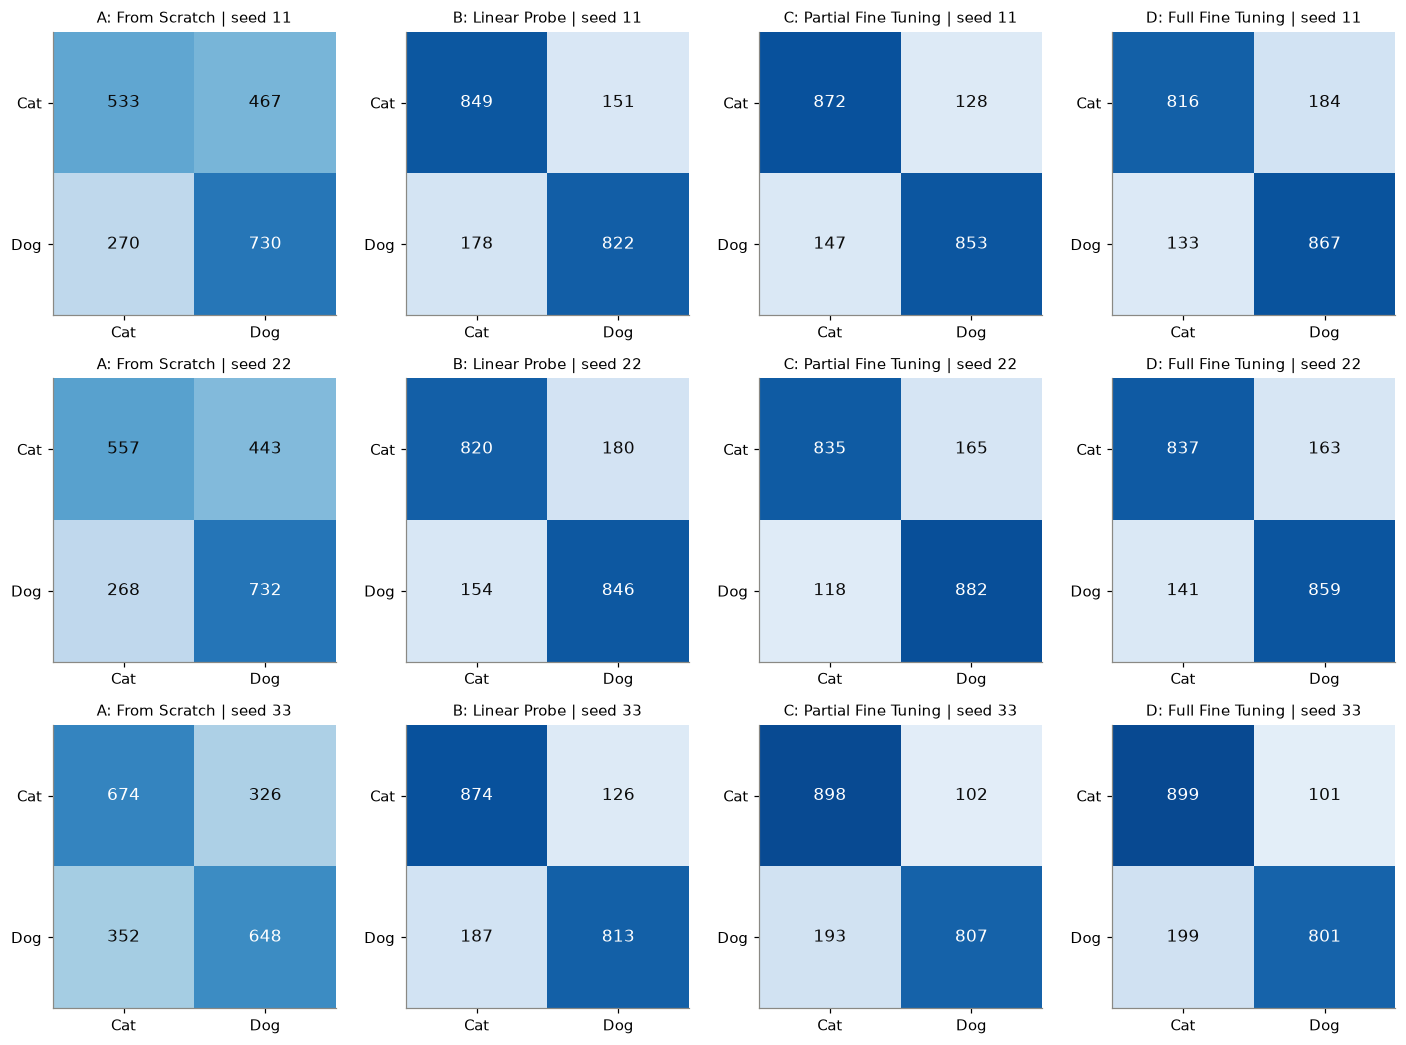

In [34]:
fig, axes = plt.subplots(len(TRAIN_SEEDS), 4, figsize=(13, 3.2 * len(TRAIN_SEEDS)), squeeze=False)
for r, seed in enumerate(TRAIN_SEEDS):
    for c, key in enumerate(EXPERIMENTS):
        run = runs[(runs.experiment == key) & (runs.seed == seed)].iloc[0]
        cm = np.array([[run.test_cm_cat_cat, run.test_cm_cat_dog], [run.test_cm_dog_cat, run.test_cm_dog_dog]])
        ax = axes[r, c]
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=1000)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=11, color="white" if cm[i, j] > 600 else "#0b0b0b")
        ax.set_xticks([0, 1], CLASS_NAMES)
        ax.set_yticks([0, 1], CLASS_NAMES)
        ax.grid(False)
        ax.set_title(f"{key}: {EXPERIMENTS[key]['name']} | seed {seed}", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "confusion_matrices.png")
plt.show()

### B. Training Behavior

#### Training and validation loss and accuracy versus epoch (mean ± std over the three seeds)

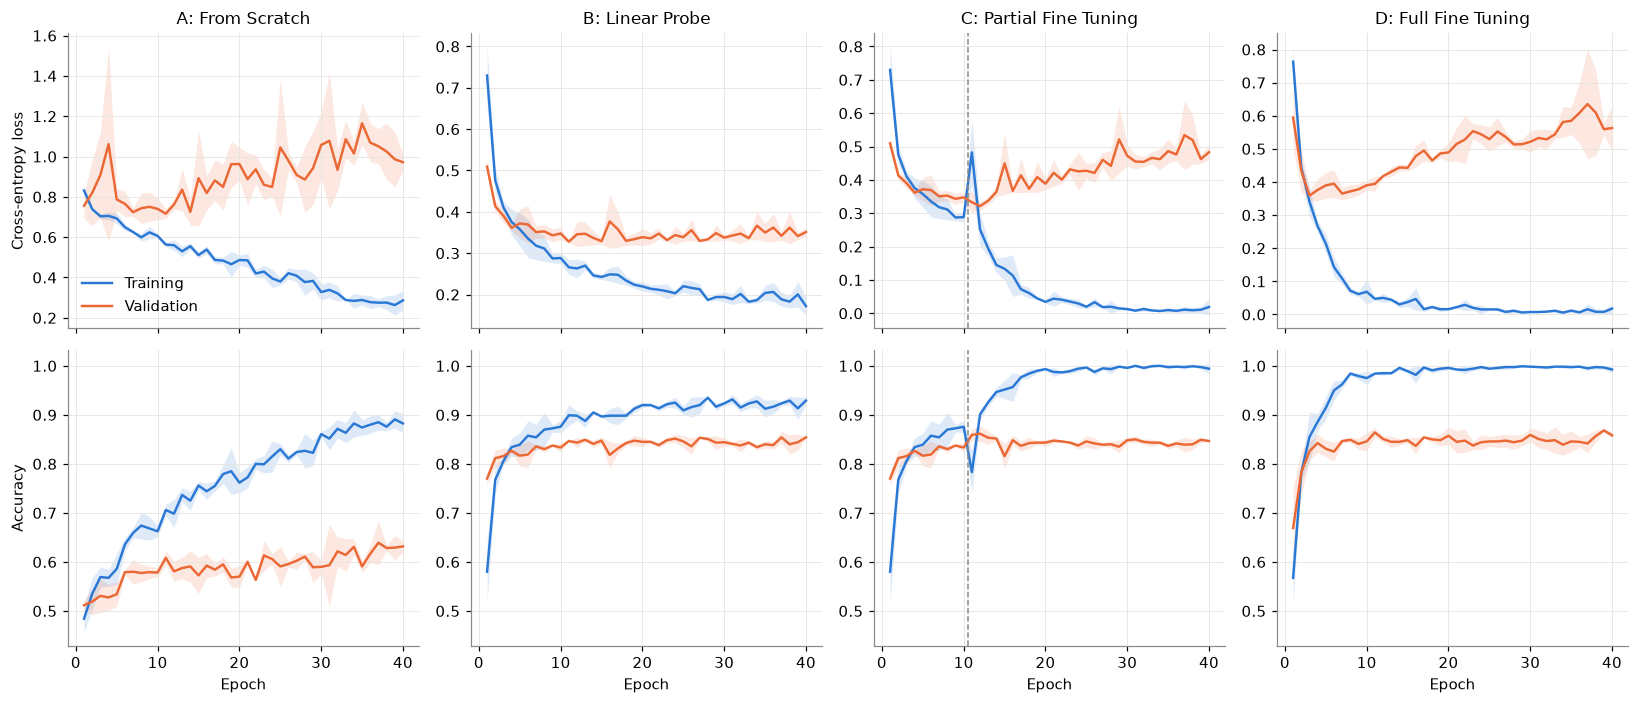

In [35]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for ax in axes[1, 1:]:
    ax.sharey(axes[1, 0])  # accuracy on one scale; loss panels keep their own (A starts much higher)
for c, (key, spec) in enumerate(EXPERIMENTS.items()):
    per_epoch = history[history.experiment == key].groupby("epoch")
    for r, metric in enumerate(["loss", "acc"]):
        ax = axes[r, c]
        for split, label, color in (("train", "Training", "#2a78d6"), ("val", "Validation", "#eb6834")):
            mean = per_epoch[f"{split}_{metric}"].mean()
            std = per_epoch[f"{split}_{metric}"].std()
            ax.plot(mean.index, mean, color=color, label=label)
            ax.fill_between(mean.index, mean - std, mean + std, color=color, alpha=0.15, linewidth=0)
        if len(spec["stages"]) > 1:
            ax.axvline(STAGE2_START - 0.5, color="#8a8984", linestyle="--", linewidth=1)
        if r == 0:
            ax.set_title(f"{key}: {spec['name']}", fontsize=11)
        else:
            ax.set_xlabel("Epoch")
axes[0, 0].set_ylabel("Cross-entropy loss")
axes[1, 0].set_ylabel("Accuracy")
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "training_curves.png")
plt.show()

#### Discuss the relationships between training performance, validation performance, and generalization

In [36]:
last = history[history.epoch == EPOCHS].set_index(["experiment", "seed"])
per_run = history.groupby(["experiment", "seed"]).agg(min_val_loss=("val_loss", "min"))
per_run["final_train_acc"] = last.train_acc
per_run["final_val_acc"] = last.val_acc
per_run["acc_gap"] = last.train_acc - last.val_acc
per_run["final_train_loss"] = last.train_loss
per_run["final_val_loss"] = last.val_loss
per_run["val_loss_rise"] = last.val_loss - per_run.min_val_loss
per_run["best_epoch"] = runs.set_index(["experiment", "seed"]).best_epoch

gap = per_run.groupby("experiment").mean().round(4)
gap

,min_val_loss,final_train_acc,final_val_acc,acc_gap,final_train_loss,final_val_loss,val_loss_rise,best_epoch
experiment,,,,,,,,
A,0.6806,0.8825,0.6317,0.2508,0.2863,0.9718,0.2912,35.6667
B,0.3232,0.9292,0.8542,0.0750,0.1719,0.3512,0.0280,25.3333
C,0.3126,0.9942,0.8467,0.1475,0.0190,0.4831,0.1706,13.6667
D,0.3514,0.9925,0.8583,0.1342,0.0177,0.5629,0.2115,23.3333


> Training accuracy rises well past validation accuracy for every strategy: C and D reach 0.99 on training while validation stays at 0.85 to 0.86 and validation loss ends 0.17 and 0.21 above its minimum; B keeps the smallest gap (0.075) and A the largest (0.25).
>
> Validation accuracy at the chosen epoch (0.855 to 0.8775 for B, C, D) sits on average 0.02 above test accuracy (0.833 to 0.8625), the expected optimism of choosing the checkpoint on a 400-image validation set.

### C. Computational Cost

In [37]:
cost = runs.groupby(["experiment", "strategy"]).agg(
    total_params=("total_params", "first"),
    trainable_params=("trainable_params", "first"),
    optimizer_steps=("optimizer_steps", "first"),
    train_time_s=("train_time_s", "mean"),
    train_time_std=("train_time_s", "std"),
    peak_memory_mb=("peak_memory_mb", "mean"),
)
cost["ms_per_step"] = 1000 * cost.train_time_s / cost.optimizer_steps
cost.round(1)

,,total_params,trainable_params,optimizer_steps,train_time_s,train_time_std,peak_memory_mb,ms_per_step
experiment,strategy,,,,,,,
A,From Scratch,11177538,11177538,520,226.7,9.4,896.2,436.1
B,Linear Probe,11177538,1026,520,43.9,4.7,150.2,84.3
C,Partial Fine Tuning,11177538,8394754,520,56.1,4.0,281.2,107.9
D,Full Fine Tuning,11177538,11177538,520,230.3,4.1,896.1,442.9


> GPU memory on Apple MPS: highest allocated memory sampled after every forward pass (MPS has no peak counter). On CUDA the same column is `torch.cuda.max_memory_allocated`.

### D. Robustness Under Distribution Shift

In [38]:
robust = runs.groupby(["experiment", "strategy"])[["test_acc", "shift_acc", "test_macro_f1", "shift_macro_f1"]].mean()
robust["f1_drop"] = robust.test_macro_f1 - robust.shift_macro_f1
robust["relative_drop_%"] = 100 * robust.f1_drop / robust.test_macro_f1
robust.round(4)

,,test_acc,shift_acc,test_macro_f1,shift_macro_f1,f1_drop,relative_drop_%
experiment,strategy,,,,,,
A,From Scratch,0.6457,0.5632,0.6435,0.5497,0.0939,14.5865
B,Linear Probe,0.8373,0.8267,0.8373,0.8264,0.0109,1.3036
C,Partial Fine Tuning,0.8578,0.8390,0.8577,0.8382,0.0195,2.2691
D,Full Fine Tuning,0.8465,0.8210,0.8463,0.8198,0.0265,3.1322


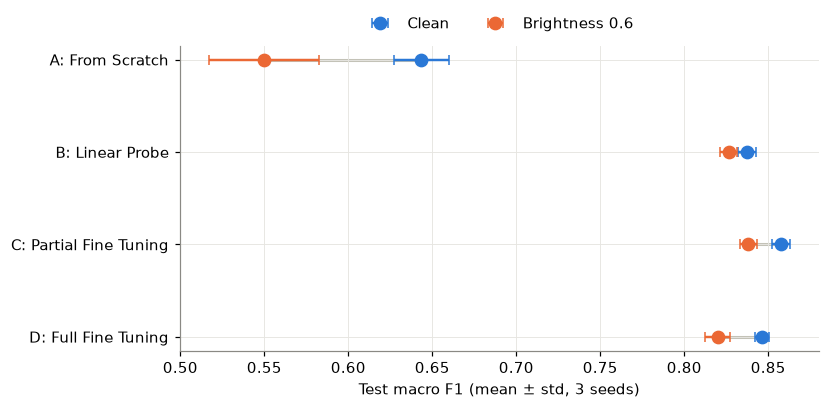

In [39]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
keys = list(EXPERIMENTS)
for y, key in enumerate(keys):
    sub = runs[runs.experiment == key]
    clean, shifted = sub.test_macro_f1, sub.shift_macro_f1
    ax.plot([shifted.mean(), clean.mean()], [y, y], color="#c3c2b7", linewidth=2, zorder=1)
    ax.errorbar(clean.mean(), y, xerr=clean.std(), fmt="o", color="#2a78d6", markersize=8, capsize=3, zorder=2,
                label="Clean" if y == 0 else None)
    ax.errorbar(shifted.mean(), y, xerr=shifted.std(), fmt="o", color="#eb6834", markersize=8, capsize=3, zorder=2,
                label="Brightness 0.6" if y == 0 else None)
ax.set_yticks(range(len(keys)), [f"{k}: {EXPERIMENTS[k]['name']}" for k in keys])
ax.invert_yaxis()
ax.set_xlabel("Test macro F1 (mean ± std, 3 seeds)")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.savefig(FIGURE_DIR / "distribution_shift.png")
plt.show()

## 7. Results and Comparison

### Mean ± sample standard deviation across the three training seeds

In [40]:
def mean_std(values, digits=4):
    return f"{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}"


table = []
for key, spec in EXPERIMENTS.items():
    sub = runs[runs.experiment == key]
    trainable = f"{sub.trainable_params.iloc[0]:,}"
    if len(spec["stages"]) > 1:
        trainable += f" ({sub.trainable_params_first_stage.iloc[0]:,} in epochs 1-{STAGE2_START - 1})"
    table.append({
        "Experiment": spec["name"],
        "Test Accuracy": mean_std(sub.test_acc),
        "Macro F1": mean_std(sub.test_macro_f1),
        "Shifted F1": mean_std(sub.shift_macro_f1),
        "Trainable Parameters": trainable,
        "Training time (s)": mean_std(sub.train_time_s, 1),
    })

summary = pd.DataFrame(table)
summary.to_csv(RESULT_DIR / "summary_table.csv", index=False)
summary

,Experiment,Test Accuracy,Macro F1,Shifted F1,Trainable Parameters,Training time (s)
0,From Scratch,0.6457 ± 0.0148,0.6435 ± 0.0166,0.5497 ± 0.0328,"11,177,538",226.7 ± 9.4
1,Linear Probe,0.8373 ± 0.0055,0.8373 ± 0.0054,0.8264 ± 0.0052,"1,026",43.9 ± 4.7
2,Partial Fine Tuning,0.8578 ± 0.0050,0.8577 ± 0.0052,0.8382 ± 0.0050,"8,394,754 (1,026 in epochs 1-10)",56.1 ± 4.0
3,Full Fine Tuning,0.8465 ± 0.0044,0.8463 ± 0.0044,0.8198 ± 0.0075,"11,177,538",230.3 ± 4.1


## 8. Scientific Discussion

### Q1. Does transferring ImageNet-pretrained representations improve performance compared with training from scratch?

In [41]:
f1 = runs.pivot(index="seed", columns="experiment", values="test_macro_f1")
for key in ["B", "C", "D"]:
    print(f"{key} - A macro F1: {f1[key].mean() - f1['A'].mean():+.4f}   (lowest {key}: {f1[key].min():.4f}, highest A: {f1['A'].max():.4f})")

B - A macro F1: +0.1937   (lowest B: 0.8330, highest A: 0.6609)
C - A macro F1: +0.2142   (lowest C: 0.8522, highest A: 0.6609)
D - A macro F1: +0.2028   (lowest D: 0.8414, highest A: 0.6609)


> Yes. Every pretrained run beats every scratch run: the worst pretrained seed (B, 0.8330) is 0.17 above the best scratch seed (A, 0.6609), and the mean gain is +0.19 to +0.21 macro F1.

### Q2. Does partial fine-tuning provide a meaningful improvement over frozen feature extraction?

In [42]:
diff = f1.C - f1.B
print("C - B macro F1 per seed:", diff.round(4).to_dict())
print(f"Mean: {diff.mean():+.4f}   Std: {diff.std():.4f}")

C - B macro F1 per seed: {11: 0.027, 22: 0.0255, 33: 0.0088}
Mean: +0.0204   Std: 0.0101


> Modestly. C beats B on every seed (+0.0270, +0.0255, +0.0088; mean +0.0204 ± 0.0101 macro F1) for about 12 s more training, but with three seeds and one gap below 0.01 the size of the gain is uncertain.

### Q3. Does full fine-tuning consistently outperform the other approaches?

In [43]:
ranks = f1.rank(axis=1, ascending=False, method="min").astype(int)
print("Rank by test macro F1 (1 = best):")
ranks

Rank by test macro F1 (1 = best):


experiment,A,B,C,D
seed,,,,
11,4,3,1,2
22,4,3,1,2
33,4,3,1,2


> No. Full fine-tuning ranks second on every seed, above B and below C (macro F1 0.8463 ± 0.0044 vs 0.8577 ± 0.0050), and it takes four times C's training time (230.3 s vs 56.1 s).

### Q4. Which strategy shows the strongest evidence of overfitting? Support your conclusion using the training and validation curves.

In [44]:
gap[["final_train_acc", "final_val_acc", "acc_gap", "final_train_loss", "final_val_loss", "val_loss_rise", "best_epoch"]].sort_values("val_loss_rise", ascending=False)

,final_train_acc,final_val_acc,acc_gap,final_train_loss,final_val_loss,val_loss_rise,best_epoch
experiment,,,,,,,
A,0.8825,0.6317,0.2508,0.2863,0.9718,0.2912,35.6667
D,0.9925,0.8583,0.1342,0.0177,0.5629,0.2115,23.3333
C,0.9942,0.8467,0.1475,0.0190,0.4831,0.1706,13.6667
B,0.9292,0.8542,0.0750,0.1719,0.3512,0.0280,25.3333


> From scratch (A): training accuracy climbs to 0.88 while validation accuracy stays at 0.63 (gap 0.25), and on the mean curve validation loss rises from 0.72 at epoch 11 to 0.97 at epoch 40 while training loss keeps falling.
>
> Among the pretrained models, D overfits most: training loss falls to 0.02 while validation loss rises from 0.36 at epoch 3 to 0.56 at epoch 40.

### Q5. How does the number of trainable parameters relate to training cost and predictive performance?

In [45]:
q5 = cost[["trainable_params", "train_time_s", "ms_per_step", "peak_memory_mb"]].copy()
q5["test_macro_f1"] = runs.groupby(["experiment", "strategy"]).test_macro_f1.mean()
q5.sort_values("trainable_params").round(4)

,,trainable_params,train_time_s,ms_per_step,peak_memory_mb,test_macro_f1
experiment,strategy,,,,,
B,Linear Probe,1026,43.8551,84.3368,150.2119,0.8373
C,Partial Fine Tuning,8394754,56.0912,107.8676,281.2484,0.8577
A,From Scratch,11177538,226.7480,436.0538,896.2265,0.6435
D,Full Fine Tuning,11177538,230.2902,442.8658,896.1119,0.8463


> Not linearly. Training cost follows how deep the backward pass goes: C trains 75% of the parameters (8,394,754) but they sit in `layer4` at the end of the network, so it needs 56.1 s and 281 MB against 230.3 s and 896 MB for D.
>
> Performance follows the initialization, not the count: A and D train the same 11,177,538 parameters at the same cost yet differ by 0.20 macro F1, and the 1,026-parameter linear probe beats A by 0.19.

### Q6. Which method is most robust under the shifted evaluation condition?

In [46]:
robust[["test_macro_f1", "shift_macro_f1", "f1_drop", "relative_drop_%"]].sort_values("shift_macro_f1", ascending=False).round(4)

,,test_macro_f1,shift_macro_f1,f1_drop,relative_drop_%
experiment,strategy,,,,
C,Partial Fine Tuning,0.8577,0.8382,0.0195,2.2691
B,Linear Probe,0.8373,0.8264,0.0109,1.3036
D,Full Fine Tuning,0.8463,0.8198,0.0265,3.1322
A,From Scratch,0.6435,0.5497,0.0939,14.5865


> By the drop, the linear probe (B): macro F1 falls 0.0109 (1.3%), against 2.3% for C, 3.1% for D and 14.6% for A, so on average the more of the ImageNet backbone stays frozen, the smaller the drop.
>
> C still has the highest shifted macro F1 (0.8382), so it remains the best model under the shift.

### Q7. Suppose you have limited computational resources for model training. Which adaptation strategy would you select? Would your choice necessarily reduce inference cost?

In [47]:
q7 = runs.groupby(["experiment", "strategy"]).agg(train_time_s=("train_time_s", "mean"), test_macro_f1=("test_macro_f1", "mean"),
                                                  test_forward_s=("test_forward_s", "mean"))
q7["inference_ms_per_image"] = 1000 * q7.test_forward_s / len(test_ids)
q7.drop(columns="test_forward_s").round(4)

,,train_time_s,test_macro_f1,inference_ms_per_image
experiment,strategy,,,
A,From Scratch,226.7480,0.6435,2.1080
B,Linear Probe,43.8551,0.8373,2.0443
C,Partial Fine Tuning,56.0912,0.8577,2.2046
D,Full Fine Tuning,230.2902,0.8463,2.2191


> Partial fine-tuning (C): the best macro F1 (0.8577) for 56.1 s and 281 MB, about a quarter of D's training time and a third of its memory. If even that is too much, the linear probe (43.9 s, 150 MB) loses only 0.02.
>
> No. All four run the same ResNet-18 forward pass at test time (2.04 to 2.22 ms per image); freezing layers only saves backward passes during training.

### Q8. Identify at least two threats to the validity of your conclusions, including any limitations associated with the choice of pretraining and target dataset.

> 1. Pretraining overlap: ImageNet-1k already contains 118 dog breeds and 5 domestic cat classes, so the pretrained features fit this task unusually well, and CIFAR-10 images are 32x32 upsampled to 224x224, far blurrier than the ImageNet photos the backbone learned from. The transfer gain may not hold for a target ImageNet does not cover.
> 2. Small samples: three seeds on one fixed split, and a 400-image validation set used both to tune learning rates and to choose checkpoints; gaps such as C vs B on seed 33 (+0.0088) are close to seed noise.
> 3. Tuning budget: learning rates were searched on seed 11 only, A's chosen rate (3e-4) sits at the edge of its grid and A was still improving at epoch 40 (mean best epoch 35.7), so training from scratch is probably under-tuned. Only one synthetic shift (brightness 0.6) was tested.

## 9. Submission Requirements

### Saved files: dataset split IDs, class mapping, results for all 12 runs, figures

In [48]:
for folder in (SPLIT_DIR, RESULT_DIR, FIGURE_DIR):
    for path in sorted(folder.iterdir()):
        print(f"{str(path):<42} {path.stat().st_size / 1024:>8.1f} KB")

print("\nRuns in results/runs.csv:", len(pd.read_csv(RESULT_DIR / "runs.csv")))

splits/class_mapping.json                       0.2 KB
splits/test_ids.csv                            42.6 KB
splits/train_ids.csv                            9.1 KB
splits/val_ids.csv                              9.1 KB
results/config.json                             1.1 KB
results/history.csv                            29.7 KB
results/lr_search.csv                           1.8 KB
results/runs.csv                                4.7 KB
results/summary_table.csv                       0.5 KB
figures/brightness_shift_examples.png         362.7 KB
figures/confusion_matrices.png                145.8 KB
figures/distribution_shift.png                 34.0 KB
figures/training_curves.png                   307.7 KB

Runs in results/runs.csv: 12


## 10. Optional Bonus

### Repeat the experiments with 50, 100 and 200 training images per class (nested subsets)
> All four experiments, three seeds, same learning rates and 40 epochs. The 200 per class runs are the main runs above.

In [49]:
BONUS_SIZES = [50, 100]
subsets = {n: train_frame[train_frame.rank_in_class < n].cifar_index.to_numpy() for n in BONUS_SIZES + [200]}

sizes = sorted(subsets)
for small, large in zip(sizes, sizes[1:]):
    print(f"{small} per class inside {large} per class:", set(subsets[small]) <= set(subsets[large]))

50 per class inside 100 per class: True
100 per class inside 200 per class: True


In [50]:
bonus_rows = []
for n in BONUS_SIZES:
    for seed in TRAIN_SEEDS:
        for key in EXPERIMENTS:
            row, _ = run_experiment(key, seed, CHOSEN_LRS[key], subsets[n], verbose=False)
            bonus_rows.append(row)
            pd.DataFrame(bonus_rows).to_csv(RESULT_DIR / "bonus_dataset_size.csv", index=False)
            print(f"{n:>3} per class | {key} | seed {seed} | steps {row['optimizer_steps']:>3} | test macro F1 {row['test_macro_f1']:.4f}")

bonus = pd.concat([pd.DataFrame(bonus_rows), runs], ignore_index=True)

 50 per class | A | seed 11 | steps 160 | test macro F1 0.5696


 50 per class | B | seed 11 | steps 160 | test macro F1 0.8070


 50 per class | C | seed 11 | steps 160 | test macro F1 0.8024


 50 per class | D | seed 11 | steps 160 | test macro F1 0.7841


 50 per class | A | seed 22 | steps 160 | test macro F1 0.5824


 50 per class | B | seed 22 | steps 160 | test macro F1 0.8040


... (14 outputs left out)

100 per class | A | seed 33 | steps 280 | test macro F1 0.5971


100 per class | B | seed 33 | steps 280 | test macro F1 0.8290


100 per class | C | seed 33 | steps 280 | test macro F1 0.8298


100 per class | D | seed 33 | steps 280 | test macro F1 0.8205


### Learning curve: test macro F1 versus labeled training images

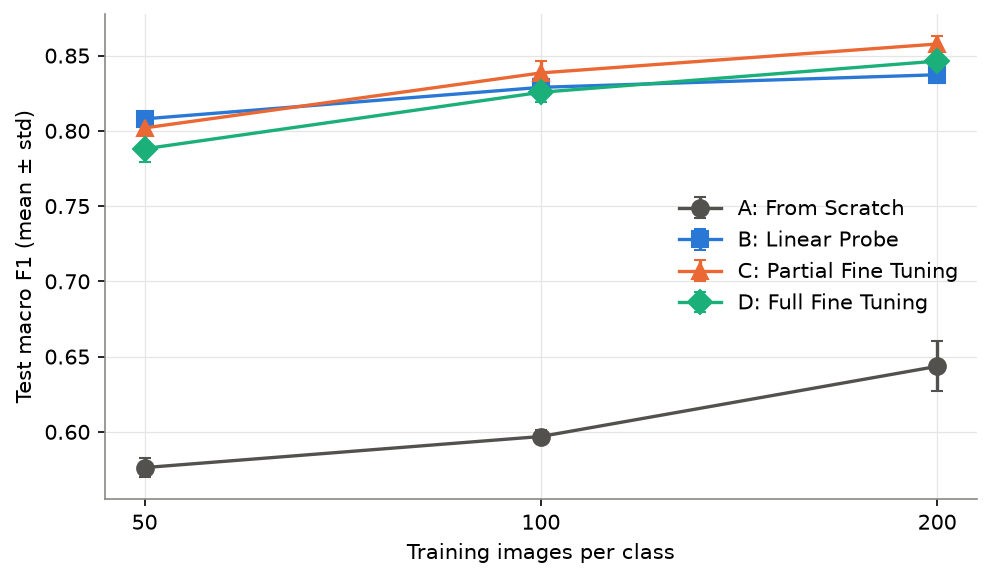

In [51]:
curve = bonus.groupby(["experiment", "train_per_class"]).test_macro_f1.agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for key, spec in EXPERIMENTS.items():
    sub = curve[curve.experiment == key]
    ax.errorbar(sub.train_per_class, sub["mean"], yerr=sub["std"], color=COLORS[key], marker=MARKERS[key],
                markersize=8, capsize=3, label=f"{key}: {spec['name']}")
ax.set_xscale("log", base=2)
ax.minorticks_off()
ax.set_xticks(sorted(curve.train_per_class.unique()), [str(n) for n in sorted(curve.train_per_class.unique())])
ax.set_xlabel("Training images per class")
ax.set_ylabel("Test macro F1 (mean ± std)")
ax.legend(frameon=False, loc="center right")
fig.savefig(FIGURE_DIR / "learning_curve.png")
plt.show()

### Which transfer-learning strategy benefits most from additional labeled data?

In [52]:
gain = curve.pivot(index="experiment", columns="train_per_class", values="mean")
gain["gain_smallest_to_200"] = gain[200] - gain[gain.columns.min()]
gain.round(4)

train_per_class,50,100,200,gain_smallest_to_200
experiment,,,,
A,0.5763,0.5969,0.6435,0.0673
B,0.8080,0.8289,0.8373,0.0293
C,0.8019,0.8385,0.8577,0.0558
D,0.7881,0.8256,0.8463,0.0583


> Among the transfer strategies, full fine-tuning gains most from 50 to 200 images per class (+0.0583), just ahead of partial fine-tuning (+0.0558); the linear probe gains least (+0.0293). It leads at 50 per class (0.8080), but C overtakes it at 100 and D at 200.
>
> A gains +0.0673 but stays far below the rest.